## Clone segmenatation github repository

> Hassan, M. O. (2025). "Brain-Tumor-Segmentation-BRISC-2025." GitHub Repository. Available at: https://github.com/mohassan5286/Brain-Tumor-Segmentation-BRISC-2025.

In [5]:
# clone github repo to temp cloud storage
!git clone https://github.com/mohassan5286/Brain-Tumor-Segmentation-BRISC-2025.git

fatal: destination path 'Brain-Tumor-Segmentation-BRISC-2025' already exists and is not an empty directory.


In [6]:
import torch

print("=== PyTorch Device & GPU Check ===")
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"CUDA Device Count: {torch.cuda.device_count()}")
    print(f"Current CUDA Device index: {torch.cuda.current_device()}")
    print(f"Current CUDA Device Name: {torch.cuda.get_device_name(0)}")
    # CUDA Memory stats
    print(f"Memory Allocated: {torch.cuda.memory_allocated(0) / 1024**3:.2f} GB")
    print(f"Memory Cached:    {torch.cuda.memory_reserved(0) / 1024**3:.2f} GB")
else:
    print("Running on: CPU (No GPU is currently connected or activated)")

=== PyTorch Device & GPU Check ===
PyTorch Version: 2.14.1+cu130
CUDA Available: True
Device: cuda
CUDA Device Count: 1
Current CUDA Device index: 0
Current CUDA Device Name: Tesla T4
Memory Allocated: 0.00 GB
Memory Cached:    0.00 GB


In [7]:
import os
import sys
import torch
import gdown
import kagglehub as kh

# github repo import
sys.path.append('/content/Brain-Tumor-Segmentation-BRISC-2025')

from model.UNet import UNet
from data.data_loader_segmentation import get_data_loader, get_test_loader
from tta_inference import predict_with_heavy_tta, set_seed

# Reproducibility
SEED = 42
set_seed(SEED)

# download dataset
BASE_DIR = kh.dataset_download("briscdataset/brisc2025")

seg_data_dir = os.path.join(BASE_DIR, "brisc2025", "segmentation_task")

test_segmentation_images = os.path.join(seg_data_dir, "test", "images")
test_segmentation_masks = os.path.join(seg_data_dir, "test", "masks")

Using Colab cache for faster access to the 'brisc2025' dataset.


In [8]:

# get the test loader
batch_size = 32
no_aug_seg_test_loader = get_test_loader(seg_data_dir, batch_size)


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [9]:
# Retain the same SEED
SEED = 42
set_seed(SEED)
batch_size = 32

# ==========================================
# CITATION / SOURCE ATTRIBUTION
# Original source code from: https://github.com/mohassan5286/Brain-Tumor-Segmentation-BRISC-2025
# Author: Hassan, M. O.
# Liscence: MIT License
# =========================================

# #######################################
# Training Data Loader Creation Function
# #######################################
seg_train_loader, seg_test_loader = get_data_loader(seg_data_dir, batch_size)

# #######################################
# Training Data Loader Creation Function
# #######################################
no_aug_seg_test_loader = get_test_loader(seg_data_dir, batch_size)

## Load best SA-TransUNet model

In [10]:
import gdown
folder_best_model = "https://drive.google.com/drive/folders/1eUHbgVAuqDQPBty_Rz8PPsF9EIr_IwAe"

output_dir = "/content/BRISC_SA-TransUNet_best_model"

# download best model if it doesn't exist
folder_best_model = "https://drive.google.com/drive/folders/1eUHbgVAuqDQPBty_Rz8PPsF9EIr_IwAe"

if not os.path.exists(os.path.join(output_dir, "best_model.pth")):
    gdown.download_folder(
        folder_best_model,
        output=output_dir,
        quiet=False
    )
# Load checkpoint
checkpoint_path = os.path.join(output_dir, "best_model.pth")
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

output_dir = "/content/BRISC_SA-TransUNet_best_model"
os.makedirs(output_dir, exist_ok=True)

gdown.download_folder(
    folder_best_model,
    output=output_dir,
    quiet=False
)

Retrieving folder contents


Processing file 1n0xJj-Wmf9Qi-N77b-Akxt0_8kDVddMc best_model.pth


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From (original): https://drive.google.com/uc?id=1n0xJj-Wmf9Qi-N77b-Akxt0_8kDVddMc
From (redirected): https://drive.google.com/uc?id=1n0xJj-Wmf9Qi-N77b-Akxt0_8kDVddMc&confirm=t&uuid=177363d4-6a44-4737-943b-ce51180b801d
To: /content/BRISC_SA-TransUNet_best_model/best_model.pth
100%|██████████| 182M/182M [00:00<00:00, 210MB/s]
Download completed
Retrieving folder contents


Processing file 1n0xJj-Wmf9Qi-N77b-Akxt0_8kDVddMc best_model.pth


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From (original): https://drive.google.com/uc?id=1n0xJj-Wmf9Qi-N77b-Akxt0_8kDVddMc
From (redirected): https://drive.google.com/uc?id=1n0xJj-Wmf9Qi-N77b-Akxt0_8kDVddMc&confirm=t&uuid=20c9989e-c11c-4b18-80c1-38c29227854f
To: /content/BRISC_SA-TransUNet_best_model/best_model.pth
100%|██████████| 182M/182M [00:01<00:00, 181MB/s]
Download completed


['/content/BRISC_SA-TransUNet_best_model/best_model.pth']

In [11]:
import os
import torch
from model.UNet import UNet

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint_path = "/content/BRISC_SA-TransUNet_best_model/best_model.pth"
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

# Instantiate UNet with the expected feature dimensions parameter
feature_dims = 64
model = UNet(in_channels=1, out_channels=1, feature_dims=feature_dims)

model.load_state_dict(checkpoint)
model = model.to(device)
model.eval()
print("Model loaded successfully!")

Model loaded successfully!


In [16]:
from test_seg import evaluate_masks
from torchmetrics.classification import BinaryJaccardIndex

iou_metric = BinaryJaccardIndex().to(device)

evaluate_masks(
    no_aug_seg_test_loader,
    model,
    iou_metric,
    device
)

Starting Evaluation on cuda...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()



:=========== TEST EVALUATION RESULTS ===========
| Glioma (GL):      0.7080 (254 instances)
| Meningioma (ME):  0.9064 (306 instances)
| Pituitary (PI):   0.8135 (300 instances)
------------------------------------------------
| WEIGHTED MEAN IoU: 0.8154
:===============================================


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


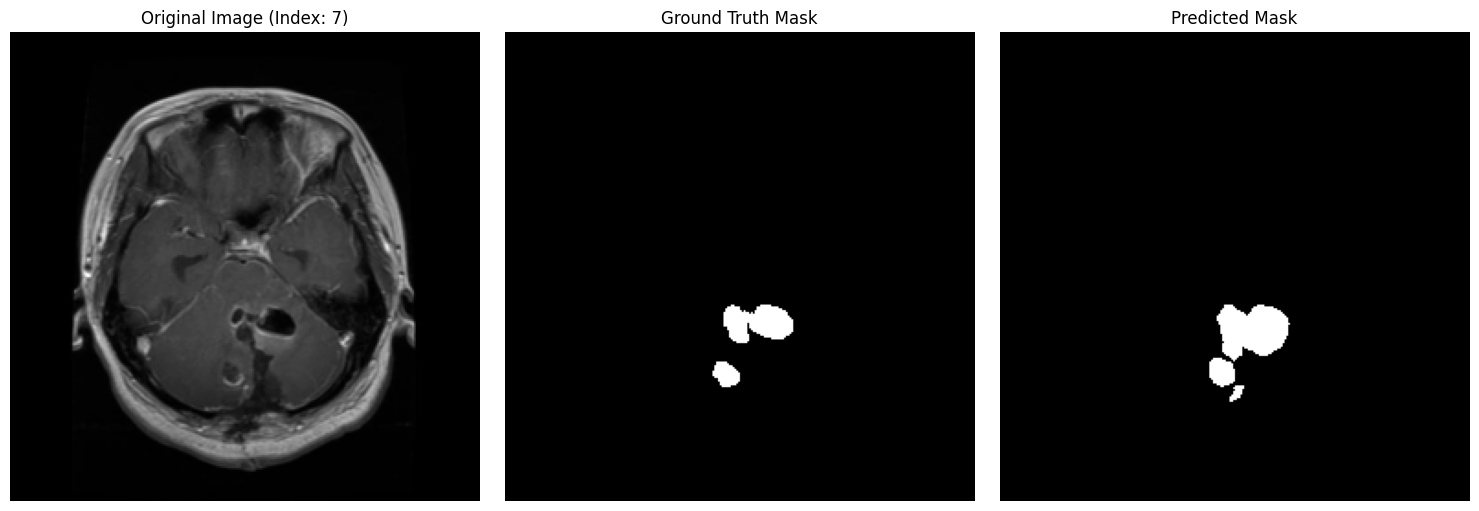

In [20]:
import matplotlib.pyplot as plt
import random

##################
# Apply inference mode
##################
model.eval()
with torch.no_grad():
    # Unpack all returned values (images, masks, and labels/metadata)
    images, masks, *labels = next(iter(no_aug_seg_test_loader))

    # Pick a random index from the current batch
    batch_size = images.size(0)
    random_idx = random.randint(0, batch_size - 1)

    # Select the random sample from the batch
    single_image = images[random_idx].unsqueeze(0).to(device)  # Shape: [1, C, H, W]
    single_mask = masks[random_idx].cpu()                      # Shape: [1, H, W]

    # Generate prediction (Note: model output already contains sigmoid activation)
    pred_probability = model(single_image)

    # Threshold at 0.5 directly to obtain the binary mask
    pred_mask = (pred_probability > 0.5).float().squeeze(0).cpu()

# ==========================================
# CITATION / SOURCE ATTRIBUTION
# Display image code generated/adapted with assistance from: Gemini (AI Assistant)
# Developer: Google
# License: Creative Commons Attribution 4.0 International
# =========================================
###########################
# Display the corresponding image
###########################
    # Move image to CPU for plotting
    plot_image = single_image.squeeze(0).cpu().permute(1, 2, 0).numpy()

    # Visualize the results
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # Plot Original Image
    axes[0].imshow(plot_image, cmap='gray' if plot_image.shape[-1] == 1 else None)
    axes[0].set_title(f"Original Image (Index: {random_idx})")
    axes[0].axis("off")

    # Plot Ground Truth Mask
    axes[1].imshow(single_mask.squeeze(), cmap='gray')
    axes[1].set_title("Ground Truth Mask")
    axes[1].axis("off")

    # Plot Predicted Mask
    axes[2].imshow(pred_mask.squeeze(), cmap='gray')
    axes[2].set_title("Predicted Mask")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()